In [43]:
%matplotlib inline 
import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy import constants
import matplotlib.pyplot as plt
import camb
MP2 = 1
Mp = 1

def omega_r(h):
    ab = (8*constants.pi**5*constants.k**4)/(15*constants.h**3*constants.c**3)
    rhor = ab*2.7255**4/(constants.c**2)
    rhov = 3.046*(7/8)*(4/11)**(4/3)*rhor
    return((rhor+rhov)/((3*(100*h)**2/(8*constants.pi*constants.G))*(1000)**2/(10**6*constants.parsec)**2))

def aseries(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
          (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2)*tau)/(a0**2*mups2*(-1 + \
            4*stigma))**(1/2) + (2500*h**2*tau**2*(omega_m))/(a0*mups2) + \
            (15625*h**3*(stigma)**(1/2)*(-1 + 4*stigma)**(1/2)*(-2 + stigma*(5 + \
            24*stigma))*tau**3*(omega_m)**2)/(a0*mups2**(3/2)*(omega_r(h))**(1/2)*(-1 + \
            stigma)*(-3 + stigma + 8*stigma**2)) + (390625*h**4*(-1 + \
            4*stigma)*(-6 + stigma*(31 + stigma*(357 + 2*stigma*(-123 + \
            5*stigma*(-151 + \
            24*stigma)))))*tau**4*(omega_m)**3)/(2*a0*mups2**2*omega_r(h)*(-1 + \
            stigma)**2*(-3 + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val

# def cpseries(tau, omega_m, h, OmL, a0, stigma, mups2):
#     val = (
#        1 - (25*h*(-1 + \
#         4*stigma)**(1/2)*tau*(omega_m))/(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)) + (1875*h**2*(-1 + \
#         4*stigma)*(2 + stigma*(-2 + \
#         3*stigma))*tau**2*(omega_m)**2)/(8*mups2*omega_r(h)*(-1 + stigma)*stigma*(-3 \
#         + stigma + 8*stigma**2))
#     )
#     return val

def cpseries(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
       1 - (25*h*(-1 + \
            4*stigma)**(1/2)*tau*(omega_m))/(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)) + (1875*h**2*(-1 + \
            4*stigma)*(2 + stigma*(-2 + \
            3*stigma))*tau**2*(omega_m)**2)/(8*mups2*omega_r(h)*(-1 + stigma)*stigma*(-3 \
            + stigma + 8*stigma**2)) + (15625*h**3*(-1 + 4*stigma)**(3/2)*(-36 + \
            stigma*(72 + stigma*(175 + stigma*(-225 + 4*stigma*(-180 + stigma*(95 \
            + 48*stigma))))))*tau**3*(omega_m)**3)/(16*mups2**(3/2)*omega_r(h)**(3/2)*(-1 + stigma)**2*stigma**(3/2)*(-3 \
            + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val

def aseriesp(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
          (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2))/(a0**2*mups2*(-1 + \
            4*stigma))**(1/2) + (5000*h**2*tau*(omega_m))/(a0*mups2) + \
            (46875*h**3*(stigma)**(1/2)*(-1 + 4*stigma)**(1/2)*(-2 + stigma*(5 + \
            24*stigma))*tau**2*(omega_m)**2)/(a0*mups2**(3/2)*(omega_r(h))**(1/2)*(-1 + \
            stigma)*(-3 + stigma + 8*stigma**2)) + (781250*h**4*(-1 + \
            4*stigma)*(-6 + stigma*(31 + stigma*(357 + 2*stigma*(-123 + \
            5*stigma*(-151 + \
            24*stigma)))))*tau**3*(omega_m)**3)/(a0*mups2**2*omega_r(h)*(-1 + \
            stigma)**2*(-3 + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val


# def cpseriesp(tau, omega_m, h, OmL, a0, stigma, mups2):
#     val = (
#         -(25*h*(-1 + \
#         4*stigma)**(1/2)*(omega_m))/(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)) + (1875*h**2*(-1 + \
#         4*stigma)*(2 + stigma*(-2 + \
#         3*stigma))*tau*(omega_m)**2)/(4*mups2*omega_r(h)*(-1 + stigma)*stigma*(-3 + \
#         stigma + 8*stigma**2))
#     )
#     return val

def cpseriesp(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        (-25*h*(-1 + \
        4*stigma)**(1/2)*(omega_m))/(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)) + (1875*h**2*(-1 + \
        4*stigma)*(2 + stigma*(-2 + \
        3*stigma))*tau*(omega_m)**2)/(4*mups2*omega_r(h)*(-1 + stigma)*stigma*(-3 + \
        stigma + 8*stigma**2)) + (46875*h**3*(-1 + 4*stigma)**(3/2)*(-36 + \
        stigma*(72 + stigma*(175 + stigma*(-225 + 4*stigma*(-180 + stigma*(95 \
        + 48*stigma))))))*tau**2*(omega_m)**3)/(16*mups2**(3/2)*omega_r(h)**(3/2)*(-1 + stigma)**2*stigma**(3/2)*(-3 \
        + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val
    
def P_deriveda0(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    return((MP2*(10000*cp**9*da*h**2*(-1 + 4*stigma**2)**3*(4*a**4*a0**4*OmL + \
            mups2*omega_r(h) + a*a0*(omega_m)) + 2*a*dcp*stigma**3*(-1 + 2*stigma)*(1 + \
            2*stigma)*(-7 + 4*stigma)*(a**2*a0**2*dcp**2*mups2 + \
            40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + a*a0*(omega_m))) + \
            2*a*cp**6*dcp*(1 - 4*stigma**2)**2*(a**2*a0**2*dcp**2*mups2*(1 - \
            4*stigma**2) + 40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + \
            a*a0*(omega_m))) - 2*a*cp**2*dcp*stigma**2*(-1 + \
            4*stigma**2)*(-(a**2*a0**2*dcp**2*mups2*(5 + 8*stigma*(1 + 2*(-2 + \
            stigma)*stigma))) + 40000*h**2*stigma*(-5 + 2*stigma)*(1 + \
            2*stigma)*(a**4*a0**4*OmL + omega_r(h) + a*a0*(omega_m))) + \
            2*a*cp**4*dcp*stigma*(-(a**2*a0**2*dcp**2*mups2*(3 + 4*(-3 + \
            stigma)*stigma)*(1 - 4*stigma**2)**2) - 120000*h**2*stigma*(-1 + \
            2*stigma)*(1 + 2*stigma)*(-1 + 4*stigma)*(a**4*a0**4*OmL + omega_r(h) + \
            a*a0*(omega_m))) + cp*da*stigma**3*(-(a**2*a0**2*dcp**2*mups2*(-1 + \
            2*stigma)*(1 + 2*stigma)*(43 + 8*stigma*(-19 + 8*stigma))) - \
            10000*h**2*stigma*(-5 + 8*stigma)*(8*a**4*a0**4*OmL*(-1 + stigma)*(1 + \
            2*stigma) + 4*omega_r(h)*(3 + 2*stigma*(-5 + 2*stigma)) + a*a0*(-7 + \
            4*stigma)*(-1 + 4*stigma)*(omega_m))) - cp**7*da*(1 - \
            4*stigma**2)**2*(3*a**2*a0**2*dcp**2*mups2*(-1 + 4*stigma**2) + \
            10000*h**2*stigma*(4*a**4*a0**4*OmL*(-11 + 2*stigma*(9 + stigma)) + \
            omega_r(h)*(4 - 8*(-1 + stigma)*stigma + mups2*(-11 + 4*stigma*(4 + stigma))) \
            - 4*a*a0*(2 + (-6 + stigma)*stigma)*(omega_m))) + \
            cp**3*da*stigma**2*(10000*h**2*omega_r(h)*stigma*(-92 - mups2*(5 - \
            8*stigma)**2*(-1 + 4*stigma**2) + 8*stigma*(21 + stigma*(69 + \
            4*stigma*(-41 + 18*stigma)))) + a*a0*(a*a0*dcp**2*mups2*(-1 + \
            2*stigma)*(1 + 2*stigma)*(43 + 8*stigma*(-1 + stigma*(-31 + 12*stigma))) \
            + 40000*h**2*stigma*(a**3*a0**3*OmL*(37 + 2*stigma*(-67 + 7*stigma*(9 \
            + 4*stigma - 8*stigma**2))) + (-2 + 5*stigma)*(4 + stigma*(11 + \
            8*stigma*(-5 + 2*stigma)))*(omega_m)))) + cp**5*da*stigma*(-1 + \
            4*stigma**2)*(10000*h**2*omega_r(h)*stigma*(mups2*(-5 + 8*stigma)*(-7 + \
            8*stigma*(1 + stigma)) - 4*(9 + 2*stigma*(1 + 2*stigma*(-13 + \
            8*stigma)))) + a*a0*(3*a*a0*dcp**2*mups2*(1 - 16*(stigma - \
            4*stigma**3 + stigma**4)) + 20000*h**2*stigma*(2*a**3*a0**3*OmL*(37 + \
            2*stigma*(-57 + 4*stigma*(9 + 4*stigma))) + (5 - 2*stigma*(30 + \
            stigma*(-57 + \
            16*stigma)))*(omega_m))))))/(a**4*cp**3*da*mups2*(-cp**2 + \
            stigma)*(-1 + 4*stigma**2)*((5 - 8*stigma)*stigma + cp**2*(-1 + \
            4*stigma**2))**2))
    
def rho_deriveda0(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    return((3*MP2*(-10000*h**2*omega_r(h) - 10000*a*h**2*(omega_m) + \
            (-(a**2*a0**2*dcp**2*mups2*(-stigma + cp**2*(1 - 4*stigma**2))) - \
            2*a*a0**2*cp*da*dcp*mups2*(stigma*(-1 + 4*stigma) + cp**2*(1 - \
            4*stigma**2)) + 40000*h**2*stigma*(-cp**2 + stigma)*(a**4*a0**4*OmL \
            + omega_r(h) + a*a0*(omega_m)))/(-(cp**2*mups2*(5 - 8*stigma)*stigma) - \
            cp**4*mups2*(-1 + 4*stigma**2))))/a**4)


# def ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
#     val = (-1/8*(120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + \
#             stigma)**2*(stigma - 4*stigma**2 + cp**2*(-1 + 4*stigma**2)) - \
#             40000*h**2*omega_r(h)*stigma*(-cp**2 + stigma)**2*(stigma - 4*stigma**2 + \
#             cp**2*(-1 + 4*stigma**2)) + a0**2*cp**2*da**2*mups2*((5 - \
#             8*stigma)*stigma + cp**2*(-1 + 4*stigma**2))*((7 - \
#             4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + \
#             cp**4*(-1 + 4*stigma**2)) + a**2*a0**2*dcp**2*mups2*(stigma**3*(-1 + \
#             4*stigma)*(1 + 8*stigma) + cp**4*stigma*(-1 + 2*stigma)*(1 + \
#             2*stigma)*(3 + 4*(-3 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
#             cp**2*stigma**2*(3 - 8*(stigma + 2*stigma**3))) + \
#             2*a*a0**2*cp*da*dcp*mups2*(cp**4*stigma*(-1 + 2*stigma)*(1 + \
#             2*stigma)*(11 + 4*(-4 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
#             stigma**3*(-1 + 16*stigma*(-2 + 3*stigma)) + cp**2*stigma**2*(11 - \
#             16*stigma*(1 + stigma*(-1 + \
#             2*stigma)))))/(a**2*a0**2*cp*mups2*stigma*(-cp**2 + stigma)**2*(-1 + \
#             4*stigma**2)))
#     return val

# def dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
#     val = (-1/8*(-(a**2*a0**2*dcp**2*mups2*(3*cp**2*stigma**2 + cp**4*(1 - \
#             2*stigma)**2*stigma*(-3 + 2*stigma)*(1 + 2*stigma) - stigma**3*(1 + \
#             8*stigma) + cp**6*(1 - 4*stigma**2)**2)) - \
#             120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + stigma)**2*(stigma + \
#             cp**2*(-1 + 4*stigma**2)) + 40000*h**2*omega_r(h)*stigma*(-cp**2 + \
#             stigma)**2*(stigma + cp**2*(-1 + 4*stigma**2)) - \
#             2*a*a0**2*cp*da*dcp*mups2*(stigma + cp**2*(-1 + 4*stigma**2))*((7 - \
#             4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + \
#             cp**4*(-1 + 4*stigma**2)) - a0**2*cp**2*da**2*mups2*(cp**4*(1 - \
#             2*stigma)**2*stigma*(-7 + 2*stigma)*(1 + 2*stigma) + stigma**3*(3 + \
#             32*(-1 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
#             cp**2*stigma**2*(3 - 16*(-1 + stigma)*stigma*(-1 + \
#             2*stigma))))/(a*a0**2*cp**2*mups2*stigma*(-cp**2 + stigma)**2*(-1 + \
#             4*stigma**2)))
#     return val

def ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        (-120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + stigma)**2*(stigma - 4*stigma**2 + cp**2*(-1 + 4*stigma**2)) + 40000*h**2*omega_r(h)*stigma*(-cp**2 + stigma)**2*(stigma - 4*stigma**2 + cp**2*(-1 + 4*stigma**2)) - a0**2*cp**2*da**2*mups2*((5 - 8*stigma)*stigma + cp**2*(-1 + 4*stigma**2))*((7 - 4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + cp**4*(-1 + 4*stigma**2)) + a**2*a0**2*dcp**2*mups2*(stigma**3 + 4*stigma**4 - 32*stigma**5 - cp**4*stigma*(-1 + 2*stigma)*(1 + 2*stigma)*(3 + 4*(-3 + stigma)*stigma) - cp**6*(1 - 4*stigma**2)**2 + cp**2*stigma**2*(-3 + 8*stigma + 16*stigma**3)) - 2*a*a0**2*cp*da*dcp*mups2*(cp**4*stigma*(-1 + 2*stigma)*(1 + 2*stigma)*(11 + 4*(-4 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + stigma**3*(-1 + 16*stigma*(-2 + 3*stigma)) + cp**2*stigma**2*(11 - 16*stigma*(1 + stigma*(-1 + 2*stigma)))))/(8*a**2*a0**2*cp*mups2*stigma*(-cp**2 + stigma)**2*(-1 + 4*stigma**2))
    )
    return val

def dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = (a**2*a0**2*dcp**2*mups2*(3*cp**2*stigma**2 + cp**4*(1 - \
        2*stigma)**2*stigma*(-3 + 2*stigma)*(1 + 2*stigma) - stigma**3*(1 + \
        8*stigma) + cp**6*(1 - 4*stigma**2)**2) + \
        120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + stigma)**2*(stigma + \
        cp**2*(-1 + 4*stigma**2)) - 40000*h**2*omega_r(h)*stigma*(-cp**2 + \
        stigma)**2*(stigma + cp**2*(-1 + 4*stigma**2)) + \
        2*a*a0**2*cp*da*dcp*mups2*(stigma + cp**2*(-1 + 4*stigma**2))*((7 - \
        4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + \
        cp**4*(-1 + 4*stigma**2)) + a0**2*cp**2*da**2*mups2*(cp**4*(1 - \
        2*stigma)**2*stigma*(-7 + 2*stigma)*(1 + 2*stigma) + stigma**3*(3 + \
        32*(-1 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
        cp**2*stigma**2*(3 - 16*(-1 + stigma)*stigma*(-1 + \
        2*stigma))))/(8*a*a0**2*cp**2*mups2*stigma*(-cp**2 + stigma)**2*(-1 \
        + 4*stigma**2))
    return val

def coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2):
    a, cp, da, dcp = y
    dydt = [da, dcp, dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2), ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2)]
    return dydt

#Initial conditions
def small(omega_m, h, stigma, mups2):
    v1_abs = (
        25*h*np.sqrt(4*stigma - 1)*omega_m
        / (2*np.sqrt(mups2)*np.sqrt(omega_r(h))*np.sqrt(stigma))
    )
    delta_varpi = min(1e-8, 1e-2*abs(1 - stigma))

    tauini = delta_varpi / v1_abs
    return tauini

#Stops for Solve_ivp
def hstop(h):
    def event(t, y):
        return y[2]-h*100
    event.terminal = True
    event.direction = 1
    return event

def astop(t, y):
    return y[0]-100

astop.terminal = True
astop.direction = 1


In [9]:
%matplotlib inline 
import numpy as np
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from scipy import constants
import matplotlib.pyplot as plt
import camb
MP2 = 1

def omega_r(h):
    ab = (8*constants.pi**5*constants.k**4)/(15*constants.h**3*constants.c**3)
    rhor = ab*2.7255**4/(constants.c**2)
    rhov = 3.046*(7/8)*(4/11)**(4/3)*rhor
    return((rhor+rhov)/((3*(100*h)**2/(8*constants.pi*constants.G))*(1000)**2/(10**6*constants.parsec)**2))

def aseries(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
          (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2)*tau)/(a0**2*mups2*(-1 + \
            4*stigma))**(1/2) + (2500*h**2*tau**2*(omega_m))/(a0*mups2) - \
            (15625*h**3*(stigma)**(1/2)*(-1 + 4*stigma)**(1/2)*(2 - stigma*(5 + \
            24*stigma))*tau**3*(omega_m)**2)/(a0*mups2**(3/2)*(omega_r(h))**(1/2)*(-1 + \
            stigma)*(-3 + stigma + 8*stigma**2)) - (390625*h**4*(-1 + \
            4*stigma)*(-6 + stigma*(31 + stigma*(357 + 2*stigma*(-123 + \
            5*stigma*(-151 + \
            24*stigma)))))*tau**4*(omega_m)**3)/(2*a0*mups2**2*omega_r(h)*(-1 + \
            stigma)**2*(-3 + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val

def cpseries(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
            1 + (25*h*(-1 + \
            4*stigma)**(1/2)*tau*(omega_m))/(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)) + (1875*h**2*(-1 + \
            4*stigma)*(2 + stigma*(-2 + \
            3*stigma))*tau**2*(omega_m)**2)/(8*mups2*omega_r(h)*(-1 + stigma)*stigma*(-3 \
            + stigma + 8*stigma**2)) - (15625*h**3*(-1 + 4*stigma)**(3/2)*(-36 + \
            stigma*(72 + stigma*(175 + stigma*(-225 + 4*stigma*(-180 + stigma*(95 \
            + 48*stigma))))))*tau**3*(omega_m)**3)/(16*mups2**(3/2)*omega_r(h)**(3/2)*(-1 + stigma)**2*stigma**(3/2)*(-3 \
            + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val

def aseriesp(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
          (200*h*(omega_r(h))**(1/2)*(stigma)**(1/2))/(a0**2*mups2*(-1 + \
            4*stigma))**(1/2) + (5000*h**2*tau*(omega_m))/(a0*mups2) - \
            (46875*h**3*(stigma)**(1/2)*(-1 + 4*stigma)**(1/2)*(2 - stigma*(5 + \
            24*stigma))*tau**2*(omega_m)**2)/(a0*mups2**(3/2)*(omega_r(h))**(1/2)*(-1 + \
            stigma)*(-3 + stigma + 8*stigma**2)) - (781250*h**4*(-1 + \
            4*stigma)*(-6 + stigma*(31 + stigma*(357 + 2*stigma*(-123 + \
            5*stigma*(-151 + \
            24*stigma)))))*tau**3*(omega_m)**3)/(a0*mups2**2*omega_r(h)*(-1 + \
            stigma)**2*(-3 + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val


def cpseriesp(tau, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        (25*h*(-1 + \
        4*stigma)**(1/2)*(omega_m))/(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2)) + (1875*h**2*(-1 + \
        4*stigma)*(2 + stigma*(-2 + \
        3*stigma))*tau*(omega_m)**2)/(4*mups2*omega_r(h)*(-1 + stigma)*stigma*(-3 + \
        stigma + 8*stigma**2)) - (46875*h**3*(-1 + 4*stigma)**(3/2)*(-36 + \
        stigma*(72 + stigma*(175 + stigma*(-225 + 4*stigma*(-180 + stigma*(95 \
        + 48*stigma))))))*tau**2*(omega_m)**3)/(16*mups2**(3/2)*omega_r(h)**(3/2)*(-1 + stigma)**2*stigma**(3/2)*(-3 \
        + stigma + 8*stigma**2)*(-6 + stigma + 20*stigma**2))
    )
    return val
    

def ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = (
        (-120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + stigma)**2*(stigma - 4*stigma**2 + cp**2*(-1 + 4*stigma**2)) + 40000*h**2*omega_r(h)*stigma*(-cp**2 + stigma)**2*(stigma - 4*stigma**2 + cp**2*(-1 + 4*stigma**2)) - a0**2*cp**2*da**2*mups2*((5 - 8*stigma)*stigma + cp**2*(-1 + 4*stigma**2))*((7 - 4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + cp**4*(-1 + 4*stigma**2)) + a**2*a0**2*dcp**2*mups2*(stigma**3 + 4*stigma**4 - 32*stigma**5 - cp**4*stigma*(-1 + 2*stigma)*(1 + 2*stigma)*(3 + 4*(-3 + stigma)*stigma) - cp**6*(1 - 4*stigma**2)**2 + cp**2*stigma**2*(-3 + 8*stigma + 16*stigma**3)) - 2*a*a0**2*cp*da*dcp*mups2*(cp**4*stigma*(-1 + 2*stigma)*(1 + 2*stigma)*(11 + 4*(-4 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + stigma**3*(-1 + 16*stigma*(-2 + 3*stigma)) + cp**2*stigma**2*(11 - 16*stigma*(1 + stigma*(-1 + 2*stigma)))))/(8*a**2*a0**2*cp*mups2*stigma*(-cp**2 + stigma)**2*(-1 + 4*stigma**2))
    )
    return val

def dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = (a**2*a0**2*dcp**2*mups2*(3*cp**2*stigma**2 + cp**4*(1 - \
        2*stigma)**2*stigma*(-3 + 2*stigma)*(1 + 2*stigma) - stigma**3*(1 + \
        8*stigma) + cp**6*(1 - 4*stigma**2)**2) + \
        120000*a**4*a0**4*h**2*OmL*stigma*(-cp**2 + stigma)**2*(stigma + \
        cp**2*(-1 + 4*stigma**2)) - 40000*h**2*omega_r(h)*stigma*(-cp**2 + \
        stigma)**2*(stigma + cp**2*(-1 + 4*stigma**2)) + \
        2*a*a0**2*cp*da*dcp*mups2*(stigma + cp**2*(-1 + 4*stigma**2))*((7 - \
        4*stigma)*stigma**2 + 2*cp**2*stigma*(1 + 2*(-3 + stigma)*stigma) + \
        cp**4*(-1 + 4*stigma**2)) + a0**2*cp**2*da**2*mups2*(cp**4*(1 - \
        2*stigma)**2*stigma*(-7 + 2*stigma)*(1 + 2*stigma) + stigma**3*(3 + \
        32*(-1 + stigma)*stigma) + cp**6*(1 - 4*stigma**2)**2 + \
        cp**2*stigma**2*(3 - 16*(-1 + stigma)*stigma*(-1 + \
        2*stigma))))/(8*a*a0**2*cp**2*mups2*stigma*(-cp**2 + stigma)**2*(-1 \
        + 4*stigma**2))
    return val

def coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2):
    a, cp, da, dcp = y
    dydt = [da, dcp, dda(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2), ddcp(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2)]
    return dydt

#Initial conditions
def small(omega_m, h, stigma, mups2):
    val = 1e-6*(2*(mups2)**(1/2)*(omega_r(h))**(1/2)*(stigma)**(1/2))/(25*h*(-1 + 4*stigma)**(1/2)*(omega_m))
    return val

#Stops for Solve_ivp
def hstop(h):
    def event(t, y):
        return y[2]-h*100
    event.terminal = True
    event.direction = 1
    return event

def astop(t, y):
    return y[0]-100

astop.terminal = True
astop.direction = 1


In [35]:
def weff2(a, cp, da, dcp, dda, ddcp, mups2, stigma, h, omega_m, a0):
    return (((2*a**2*dcp)/cp + (2*a**2*cp*dcp*(-1 + 4*stigma**2))/((5 - \
        8*stigma)*stigma + cp**2*(-1 + 4*stigma**2)) + \
        (da*(120000*a**4*a0**4*h**2*OmL*(cp**2 - stigma)*stigma + \
        40000*h**2*omega_r(h)*stigma*(-cp**2 + stigma) - \
        a**2*a0**2*mups2*(2*cp*ddcp*(stigma - 4*stigma**2 + cp**2*(-1 + \
        4*stigma**2)) + dcp**2*((3 - 8*stigma)*stigma + 7*cp**2*(-1 + \
        4*stigma**2)))) + 2*a*dcp*(-(a**2*a0**2*ddcp*mups2*(stigma + \
        cp**2*(-1 + 4*stigma**2))) + cp*(40000*h**2*omega_r(h)*stigma + \
        a*a0*(40000*a**3*a0**3*h**2*OmL*stigma - a*a0*dcp**2*mups2*(-1 + \
        4*stigma**2) - a0*dda*mups2*(stigma - 4*stigma**2 + cp**2*(-1 + \
        4*stigma**2)) + \
        40000*h**2*stigma*(omega_m)))))/(a0**2*(-2*cp*da*dcp*mups2*(stigma*(-1 + 4*stigma) + cp**2*(1 - \
        4*stigma**2)) + a*dcp**2*mups2*(stigma + cp**2*(-1 + 4*stigma**2)) + \
        (40000*h**2*stigma*(-cp**2 + stigma)*(a**4*a0**4*OmL + omega_r(h) + \
        a*a0*(omega_m)))/(a*a0**2))))/(3*a*da))

In [36]:
def constraint(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    val = (3*a*Mp**2*((-2*cp*da*dcp*mups2)/a - dcp**2*mups2 - (4*(((-1 + \
        cp**2)*da)/a + cp*dcp)**2*mups2*stigma**2)/(-cp**2 + stigma) + \
        (da**2*mups2*(-cp**2 + 4*stigma))/a**2 - (40000*h**2*stigma*(a**4*OmL \
        + omega_r(h) + a*(omega_m)))/a**2))/(4*stigma)
    # val = ((-2*cp*da*dcp*mups2)/a - dcp**2*mups2 - (4*(((-1 + cp**2)*da)/a + \
    #         cp*dcp)**2*mups2*stigma**2)/(-cp**2 + stigma) + (da**2*mups2*(-cp**2 + \
    #         4*stigma))/a**2 - (40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h) + \
    #         a*a0*(omega_m)))/(a**2*a0**2))
    return val

In [37]:
def constraint(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    """Relative constraint violation: C / sum(|terms|).  Dimensionless,
    bounded, safe at turnarounds (da=0) and near the wall (cp^2 -> stigma).
    ~1e-7 means the five terms cancel to 7 digits."""
    pref = 3*a*a0*MP2/(4*stigma)
    X = ((-1 + cp**2)*da)/a + cp*dcp

    t_src   = pref * (-(40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h)
                                           + a*a0*omega_m))/(a**2*a0**2))
    t_da2   = pref * (da**2*mups2*(-cp**2 + 4*stigma))/a**2
    t_cross = pref * (-2*cp*da*dcp*mups2)/a
    t_dcp2  = pref * (-dcp**2*mups2)
    t_X2    = pref * (-4*X**2*mups2*stigma**2)/(-cp**2 + stigma)

    C      = t_src + t_da2 + t_cross + t_dcp2 + t_X2
    T_norm = (np.abs(t_src) + np.abs(t_da2) + np.abs(t_cross)
              + np.abs(t_dcp2) + np.abs(t_X2))
    return C

In [38]:
def constraint_ratio(a, da, cp, a0, stigma, mups2):
    a0 = 1
    T_hd = 3*a*a0*Mp**2/(4*stigma) * \
           (da**2*mups2*(-cp**2 + 4*stigma))/a**2
    return T_hd

In [39]:
def G(a, da, cp, dcp, stigma, mups, a0):
    val = (-4*a0**4*da**2*stigma*(-cp**2 + stigma))/(mups2*(-(cp**4*da**2) - 2*a*cp**3*da*dcp - a**2*cp**2*dcp**2 + 5*cp**2*da**2*stigma + 2*a*cp*da*dcp*stigma + a**2*dcp**2*stigma - 8*cp**2*da**2*stigma**2 + 4*cp**4*da**2*stigma**2 - 8*a*cp*da*dcp*stigma**2 + 8*a*cp**3*da*dcp*stigma**2 + 4*a**2*cp**2*dcp**2*stigma**2)) 
    return val

In [42]:
eps_init = min(1e-8, 1e-2 * abs(1 - stigma))
tauini = eps_init / abs(v1)

NameError: name 'v1' is not defined

In [44]:
def rhopsol(omega_m, h, OmL, stigma, mups2):

    tauini = small(omega_m, h, stigma, mups2)
    print(tauini)
    
    y0 = [aseries(tauini, omega_m, h, OmL, 1, stigma, mups2), cpseries(tauini, omega_m, h, OmL, 1, stigma, mups2),
          aseriesp(tauini, omega_m, h, OmL, 1, stigma, mups2), cpseriesp(tauini, omega_m, h, OmL, 1, stigma, mups2)]
    print(y0)
    sol = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, 1, stigma, mups2),
                    [tauini, np.inf], y0,  events = hstop(h), rtol=1e-12, atol=1e-12)
    # Find a0.
    a0 = 1
    
    y02 = [aseries(tauini, omega_m, h, OmL, a0, stigma, mups2), cpseries(tauini, omega_m, h, OmL, a0, stigma, mups2),
          aseriesp(tauini, omega_m, h, OmL, a0, stigma, mups2), cpseriesp(tauini, omega_m, h, OmL, a0, stigma, mups2)]
    
    sola0 = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2),
                    [tauini, np.inf], y02, events = astop, rtol=1e-12, atol=1e-12)
    
    tsol = interp1d(sola0.y[0], sola0.t, bounds_error = False)
    avals = np.logspace(np.log10(sola0.y[0][0]),2,10000)
    tvals = tsol(avals)
    tvals[0] = tauini
    avals[0] = sola0.y[0][0]
    
    
    sola02 = solve_ivp(lambda tau, y: coupdiff(y, tau, omega_m, h, OmL, a0, stigma, mups2),
                    [tauini, np.inf], y02, t_eval = tvals, events = astop, rtol=1e-12, atol=1e-12)
    
    asol, varpisol, hsol, dvarpisol = sola02.y
    aend, vpend, hend, dvpend = sola02.y_events[0][0]

    if aend > asol[-1]:
        asol = np.append(asol, aend)
        hsol = np.append(hsol, hend)
        varpisol = np.append(varpisol, vpend)
        dvarpisol = np.append(dvarpisol, dvpend)


    hubble = (a0* hsol)/asol**2
    z = 1/asol-1
    
    constrain = constraint(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, mups2)
    ddasol = dda(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, mups2) 
    Gi = G(asol, hsol, varpisol, dvarpisol, stigma, mups2, a0)
    T_hd = constraint_ratio(asol, hsol, varpisol, a0, stigma, mups2)
    ddasol = dda(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, mups2)
    ddcpsol = ddcp(asol, hsol, varpisol, dvarpisol, omega_m, h, OmL, a0, stigma, mups2)


    return asol, varpisol, hsol, dvarpisol, a0, constrain, ddasol, Gi,T_hd

In [56]:
h = 0.7
Mp = 1
H0 = h*100
stigma = 0.9
mups2 = 4/3
ombh2=0.02242
omch2=0.11933
omega_m = (ombh2+omch2)/h**2
OmL = 0.9

# ── 4. THEORY CURVE ───────────────────────────────────────────────────────────

asol, varpisol, hsol, dvarpisol, a0, constrain, ddasol, Gi,T_hd = rhopsol(omega_m, h, OmL, stigma, mups2)

2.4799976967632397e-11
[np.float64(1.6346579800485465e-11), np.float64(0.9999999899999991), np.float64(0.6591369010255883), np.float64(-403.2262535736126)]


KeyboardInterrupt: 

In [46]:
constraint_2 #(km/s/Mpc)²

NameError: name 'constraint_2' is not defined

In [47]:
def constraint_rel(a, da, cp, dcp, omega_m, h, OmL, a0, stigma, mups2):
    """Relative constraint violation: C / sum(|terms|).  Dimensionless,
    bounded, safe at turnarounds (da=0) and near the wall (cp^2 -> stigma).
    ~1e-7 means the five terms cancel to 7 digits."""
    pref = 3*a*a0*MP2/(4*stigma)
    X = ((-1 + cp**2)*da)/a + cp*dcp

    t_src   = pref * (-(40000*h**2*stigma*(a**4*a0**4*OmL + omega_r(h)
                                           + a*a0*omega_m))/(a**2*a0**2))
    t_da2   = pref * (da**2*mups2*(-cp**2 + 4*stigma))/a**2
    t_cross = pref * (-2*cp*da*dcp*mups2)/a
    t_dcp2  = pref * (-dcp**2*mups2)
    t_X2    = pref * (-4*X**2*mups2*stigma**2)/(-cp**2 + stigma)

    C      = t_src + t_da2 + t_cross + t_dcp2 + t_X2
    T_norm = (np.abs(t_src) + np.abs(t_da2) + np.abs(t_cross)
              + np.abs(t_dcp2) + np.abs(t_X2))
    return C / T_norm

In [48]:
constrain

array([ 1.93205020e-05,  1.60215559e-05, -2.60595458e-06, ...,
        1.41859055e-05, -4.40180302e-04, -6.96122646e-04], shape=(10000,))

In [49]:
constrain

array([ 1.93205020e-05,  1.60215559e-05, -2.60595458e-06, ...,
        1.41859055e-05, -4.40180302e-04, -6.96122646e-04], shape=(10000,))

In [50]:
constraint_2

NameError: name 'constraint_2' is not defined

Text(0, 0.5, '(km/s/Mpc)²')

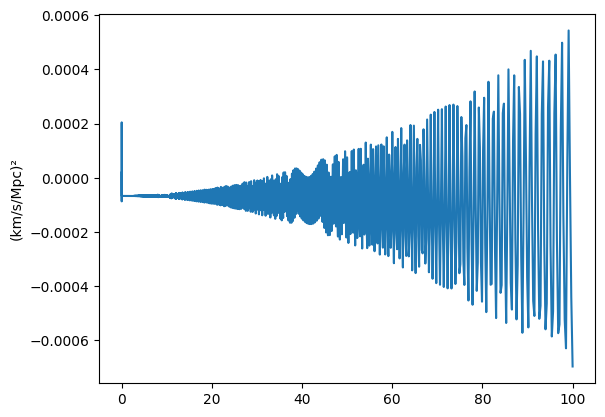

In [51]:
plt.plot(asol,constrain)
plt.ylabel("(km/s/Mpc)²")

In [52]:
def cpsq_minus(stigma, wi):
    val = ((stigma*(1 + 2*(-3 + stigma)*stigma + (-3 + 6*stigma*(1 + stigma))*wi) - 2*((-1 + stigma)**2*stigma**2*(2 - 6*wi + (stigma + 3*stigma*wi)**2))**(1/2))/((-1 + 4*stigma**2)*(-1 + 3*wi))) 
    return val

def cpsq_plus(stigma, wi):
    val = ((stigma*(1 + 2*(-3 + stigma)*stigma + (-3 + 6*stigma*(1 + stigma))*wi) + 2*((-1 + stigma)**2*stigma**2*(2 - 6*wi + (stigma + 3*stigma*wi)**2))**(1/2))/((-1 + 4*stigma**2)*(-1 + 3*wi)))
    return val

In [53]:
def cpsq_test(stigma, wi):
    val = ((stigma*(1 + 2*(-3 + stigma)*stigma + (-3 + 6*stigma*(1 + stigma))*wi) \
+ 2*((-1 + stigma)**2*stigma**2*(2 - 6*wi + (stigma + \
3*stigma*wi)**2))**(1/2))/((-1 + 4*stigma**2)*(-1 + 3*wi)))
    return val

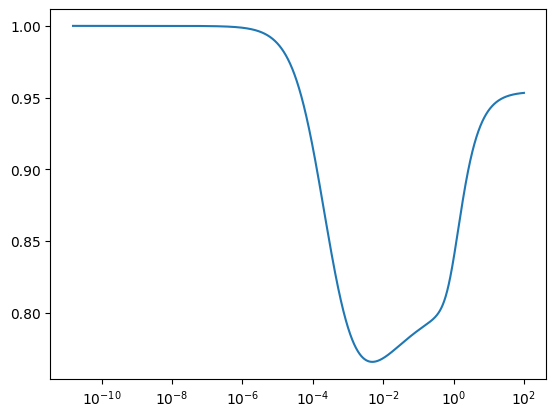

In [54]:
plt.plot(asol, varpisol**2)
plt.xscale("log")

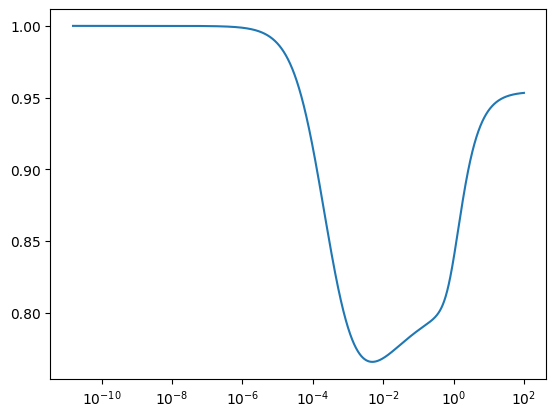

In [55]:
plt.plot(asol, varpisol**2)
plt.xscale("log")

In [32]:
np.max(np.abs(constrain))

np.float64(2362.50623100996)

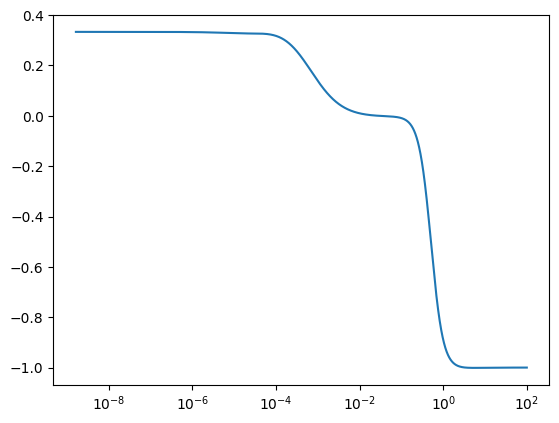

In [33]:
weff = 1/3-(2*asol*ddasol)/(3*hsol**2)
import matplotlib.pyplot as plt
plt.plot(asol, weff)
plt.xscale("log")

In [189]:
print(weff)
print(weff2sol)

[ 0.333332    0.333332    0.33333199 ... -0.99990182 -0.99990212
 -0.99990241]
[ 0.333332    0.333332    0.33333199 ... -0.99990182 -0.99990212
 -0.99990241]


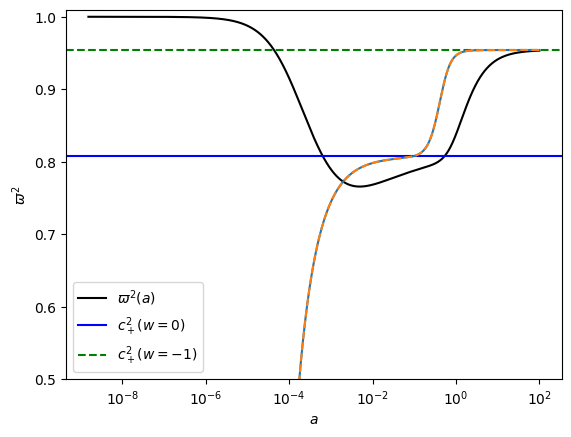

In [190]:
plt.plot(asol, varpisol**2,
         color="black",
         label=r"$\varpi^2(a)$")

plt.axhline(cpsq_plus(stigma, 0),
            color="blue",
            label=r"$c_+^2(w=0)$")

plt.axhline(cpsq_plus(stigma, -1),
            color="green",
            ls="--",
            label=r"$c_+^2(w=-1)$")

plt.plot(asol, cpsq_plus(stigma, weff))
plt.plot(asol, cpsq_plus(stigma, weff2sol), "--")

plt.ylim(0.5,1.01)

plt.xscale("log")

plt.xlabel(r"$a$")
plt.ylabel(r"$\varpi^2$")

plt.legend()

plt.show()

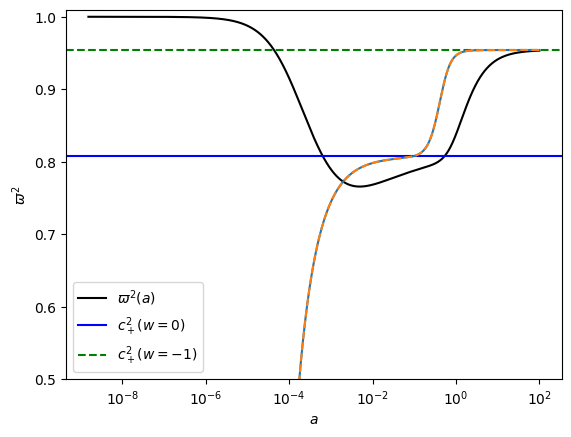

In [191]:
plt.plot(asol, varpisol**2,
         color="black",
         label=r"$\varpi^2(a)$")

plt.axhline(cpsq_plus(stigma, 0),
            color="blue",
            label=r"$c_+^2(w=0)$")

plt.axhline(cpsq_plus(stigma, -1),
            color="green",
            ls="--",
            label=r"$c_+^2(w=-1)$")

plt.plot(asol, cpsq_plus(stigma, weff))
plt.plot(asol, cpsq_plus(stigma, weff2sol), "--")

plt.ylim(0.5,1.01)

plt.xscale("log")

plt.xlabel(r"$a$")
plt.ylabel(r"$\varpi^2$")

plt.legend()

plt.show()

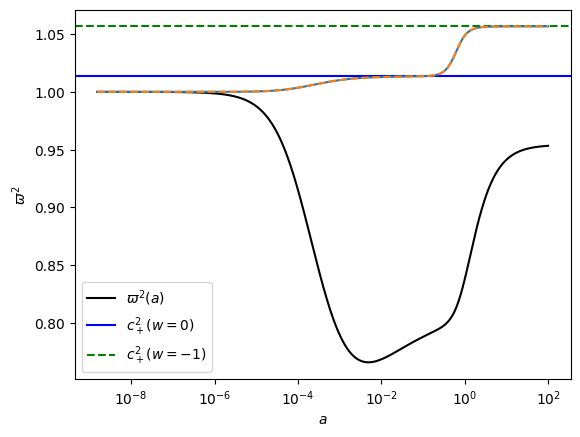

In [192]:
plt.plot(asol, varpisol**2,
         color="black",
         label=r"$\varpi^2(a)$")

plt.axhline(cpsq_minus(stigma, 0),
            color="blue",
            label=r"$c_+^2(w=0)$")

plt.axhline(cpsq_minus(stigma, -1),
            color="green",
            ls="--",
            label=r"$c_+^2(w=-1)$")

plt.plot(asol, cpsq_minus(stigma, weff))
plt.plot(asol, cpsq_minus(stigma, weff2sol), "--")

# plt.ylim(0.99,1.6)

plt.xscale("log")

plt.xlabel(r"$a$")
plt.ylabel(r"$\varpi^2$")

plt.legend()

plt.show()

In [404]:
weffofa = interp1d(asol, weff, bounds_error = False)

In [405]:
weffofa(0.001)

array(0.07342786)

In [406]:
def gi_sol(stigma, wi,mups2, a0):
    return ((-4*a0**4*stigma*(-1 + 3*wi))/(mups2*(stigma*(3 - 9*wi) - stigma**3*(1 + 3*wi)**2 + (stigma + 3*stigma*wi)**2 + (1 + 3*wi)*((-1 + stigma)**2*stigma**2*(2 - 6*wi + (stigma + 3*stigma*wi)**2))**(1/2))))

def gi_sol_2(stigma, wi,mups2, a0):
    return (-4*a0**4*stigma*(1 - 3*wi))/(mups2*(stigma**3*(1 + 3*wi)**2 + stigma*(-3 + 9*wi) - (stigma + 3*stigma*wi)**2 + (1 + 3*wi)*((-1 + stigma)**2*stigma**2*(2 - 6*wi + (stigma + 3*stigma*wi)**2))**(1/2)))

In [266]:
print(gi_sol(stigma, 1/3,mups2, a0), gi_sol_2(stigma, 1/3,mups2, a0),
    gi_sol(stigma, 0,mups2, a0), gi_sol_2(stigma, 0,mups2, a0),
     gi_sol(stigma, -1,mups2, a0), gi_sol_2(stigma, -1,mups2, a0))

-0.0 -0.0 0.9044623134736165 1.0082243558619715 1.0082243558619712 0.9044623134736164


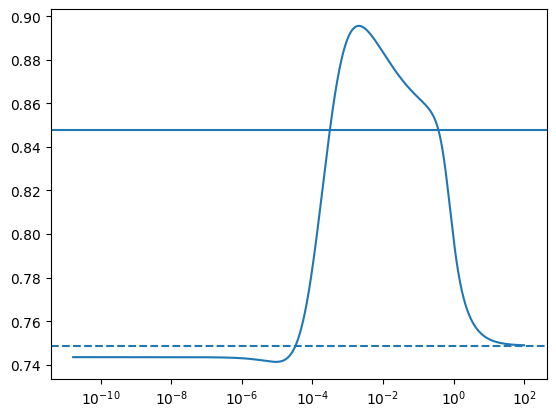

In [298]:
plt.plot(asol, Gi)
plt.axhline(gi_sol_2(stigma, 0,mups2, a0))
plt.axhline(gi_sol_2(stigma, -1,mups2, a0), ls = "--")
plt.xscale("log")

In [977]:
h = 0.7
h*100 = 100*h
OmL = 0.5
stigma = 1.1
mups2 = 1.
cpr = 0.9
ombh2=0.02242
omch2=0.11933
omega_m = (ombh2+omch2)/h**2

# ── 4. THEORY CURVE ───────────────────────────────────────────────────────────

z_arr, H_arr,P_DE, rho_DE, asol = rhopsol(omega_m, h, OmL, stigma, mups2)

2.0763674520390663e-09
[1.527819101770248e-09, 0.9999990000066131, 0.7358141874925556, -481.6039534798611]


ValueError: too many values to unpack (expected 5)

In [82]:
import camb
pars = camb.CAMBparams()
pars.set_cosmology(h*100=h*100, ombh2=ombh2, omch2=omch2, omk=0)
pars.set_dark_energy_rho_p_a(a_p=asol, a_rho=asol,p=P_DE, rho=rho_DE)
pars.set_for_lmax(2500, lens_potential_accuracy=0)
pars.InitPower.set_params(As=2.1e-9, ns=0.965, r=0)
a
results = camb.get_background(pars)
rd_theory      = results.get_derived_params()['rdrag']  # Mpc
h*100rd_theory    = h*100 * rd_theory                                # km/s

In [53]:
def H(a, omega_m, h):
    val = (h*100)*np.sqrt((omega_m*(a)**-3+omega_r(h)*(a)**-4+(1-omega_m-omega_r(h))))
    return val

In [54]:
H(1, omega_m, h)

np.float64(70.0)

In [55]:
import numpy as np
from scipy.interpolate import interp1d
from scipy.integrate import quad
from scipy.optimize import minimize
from scipy.stats import multivariate_normal
from pandas import read_csv
import matplotlib
import matplotlib.pyplot as plt
c_kms = 299792.458  # km/s
omegar = 8.24e-5

# ── 2. LCDM REFERENCE (fit to DESI DR2) ──────────────────────────────────────

# Load DESI DR2 data
data = read_csv("../../data/desidr2/desidr2_mean.txt",
                header=None, index_col=None, sep=r"\s+", comment="#")
cov = np.loadtxt("../../data/desidr2/desidr2_cov.txt")

zs = data.iloc[:, 0].to_numpy()
mean_data = data.iloc[:, 1].to_numpy()
types = data.iloc[:, 2].to_numpy()
cov_inv = np.linalg.inv(cov)

def E_lcdm(z, omegam):
    return np.sqrt(omegam*(1+z)**3 + omegar*(1+z)**4 + (1-omegam-omegar))

def dm_lcdm(z, h*100rd, omegam):
    integral, _ = quad(lambda zp: 1/E_lcdm(zp, omegam), 0, z)
    return c_kms / h*100rd * integral

def dh_lcdm(z, h*100rd, omegam):
    return c_kms / h*100rd / E_lcdm(z, omegam)

def dv_lcdm(z, h*100rd, omegam):
    return (z * dm_lcdm(z, h*100rd, omegam)**2 * dh_lcdm(z, h*100rd, omegam))**(1/3)

def chi2_lcdm(params):
    h*100rd, omegam = params
    if omegam <= 0 or omegam >= 1 or h*100rd <= 0:
        return 1e10
    fns = {"DM_over_rs": dm_lcdm, "DH_over_rs": dh_lcdm, "DV_over_rs": dv_lcdm}
    pred = [fns[t](z, h*100rd, omegam) for z, t in zip(zs, types)]
    return (mean_data - pred) @ cov_inv @ (mean_data - pred)

result = minimize(chi2_lcdm, x0=[10145, 0.298], method='Nelder-Mead',
                  options={'xatol': 1e-6, 'fatol': 1e-12, 'maxiter': 10000})
h*100rd_bf, omegam_bf = result.x
print(f"ΛCDM best fit: h*100rd = {h*100rd_bf:.1f} km/s,  Ωm = {omegam_bf:.4f}")

def lcdm_ratio(z):
    integral, _ = quad(lambda zp: 1/E_lcdm(zp, omegam_bf), 0, z)
    return E_lcdm(z, omegam_bf) * integral / z


# ── 3. DESI DR2 DATA POINTS ───────────────────────────────────────────────────

np.random.seed(42)
samples = multivariate_normal(mean_data, cov).rvs(10_000)

dmidx = types == "DM_over_rs"
dhidx = types == "DH_over_rs"
dm_s = samples[:, dmidx]
dh_s = samples[:, dhidx]
zm = zs[dmidx]

ratio = dm_s / (zm * dh_s)
ratio_mean = ratio.mean(axis=0)
ratio_std = ratio.std(axis=0)
residuals = ratio_mean - np.array([lcdm_ratio(z) for z in zm])

labels = ["LRG", "LRG", "LRG+ELG", "ELG", "QSO", r"Ly-$\alpha$"]
colors = ['C6', 'C4', 'C3', 'C3', 'C2', 'C1']
a_vals = 1 / (1 + zm)



ΛCDM best fit: H0rd = 10157.4 km/s,  Ωm = 0.2969


In [62]:
h = 0.7
h*100 = 100*h
OmL = 0.7
stigma = 1.01
mups2 = 1.22
cpr = 0.999
ombh2=0.02242
omch2=0.11933
omega_m = (ombh2+omch2)/h**2

# ── 4. THEORY CURVE ───────────────────────────────────────────────────────────

z_arr, H_arr,P_DE, rho_DE, asol = rhopsol(cpr, omega_m, h, OmL, stigma, mups2)
h_interp = interp1d(z_arr, H_arr / H_arr[0], kind='cubic')

NameError: name 'a_vals' is not defined

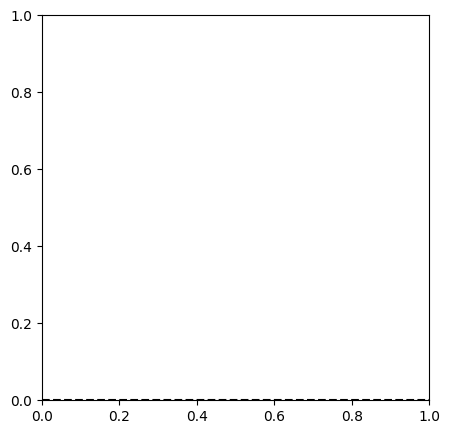

In [785]:
def theory_ratio(z):
    integral, _ = quad(lambda zp: 1/float(h_interp(zp)), 0, z)
    return float(h_interp(z)) * integral / z


# ── 5. PLOT ───────────────────────────────────────────────────────────────────

fig, ax = plt.subplots(figsize=(5, 5))
ax.axhline(0, color='k', linestyle='--')

for a, res, err, label, color in zip(a_vals, residuals, ratio_std, labels, colors):
    ax.errorbar(a, res, yerr=err, marker='+', markersize=8, linewidth=1.5,
                color=color, label=label, capsize=0)

a_plot = np.linspace(0.01, 0.99, 200)
z_plot = 1 / a_plot - 1
theory_res = np.array([theory_ratio(z) - lcdm_ratio(z) for z in z_plot])
ax.plot(a_plot, theory_res, color='k', linewidth=1.5, label='My theory')

ax.set(
    xlabel=r'$a$',
    ylabel=r'$D_\mathrm{M}/(zD_H) - (D_\mathrm{M}/(zD_H))_{\Lambda\mathrm{CDM}}$',
    xlim=(0, 1),
    ylim=(-0.25, 0.25),
    title='DESI DR2',
)
ax.legend(fontsize='small')
fig.tight_layout()

In [64]:
import camb
pars = camb.CAMBparams()
pars.set_cosmology(h*100=h*100, ombh2=ombh2, omch2=omch2, omk=0)
pars.set_dark_energy_rho_p_a(a_p=asol, a_rho=asol,p=P_DE, rho=rho_DE)
pars.set_for_lmax(2500, lens_potential_accuracy=0)
pars.InitPower.set_params(As=2.1e-9, ns=0.965, r=0)
a
results = camb.get_background(pars)
rd_theory      = results.get_derived_params()['rdrag']  # Mpc
h*100rd_theory    = h*100 * rd_theory                                # km/s

In [858]:
import numpy as np
from scipy.stats import multivariate_normal
from scipy.integrate import quad
from scipy.optimize import minimize
from pandas import read_csv
import matplotlib
import matplotlib.pyplot as plt

c_kms = 299792.458  # km/s
omegar = 8.24e-5

# ── Load DESI DR2 data ────────────────────────────────────────────────────────

data = read_csv("../../data/desidr2/desidr2_mean.txt",
                header=None, index_col=None, sep=r"\s+", comment="#")
cov = np.loadtxt("../../data/desidr2/desidr2_cov.txt")

zs = data.iloc[:, 0].to_numpy()
mean_data = data.iloc[:, 1].to_numpy()
types = data.iloc[:, 2].to_numpy()
cov_inv = np.linalg.inv(cov)

# ── Fit (h*100rd, Ωm) under flat ΛCDM to all data ───────────────────────────────

def E(z, omegam):
    return np.sqrt(omegam*(1+z)**3 + omegar*(1+z)**4 + (1-omegam-omegar))

def dm_lcdm(z, h*100rd, omegam):
    integral, _ = quad(lambda zp: 1/E(zp, omegam), 0, z)
    return c_kms / h*100rd * integral

def dh_lcdm(z, h*100rd, omegam):
    return c_kms / h*100rd / E(z, omegam)

def dv_lcdm(z, h*100rd, omegam):
    return (z * dm_lcdm(z, h*100rd, omegam)**2 * dh_lcdm(z, h*100rd, omegam))**(1/3)

def chi2(params):
    h*100rd, omegam = params
    if omegam <= 0 or omegam >= 1 or h*100rd <= 0:
        return 1e10
    fns = {"DM_over_rs": dm_lcdm, "DH_over_rs": dh_lcdm, "DV_over_rs": dv_lcdm}
    pred = [fns[t](z, h*100rd, omegam) for z, t in zip(zs, types)]
    return (mean_data - pred) @ cov_inv @ (mean_data - pred)

result = minimize(chi2, x0=[10145, 0.298], method='Nelder-Mead',
                  options={'xatol': 1e-6, 'fatol': 1e-12, 'maxiter': 10000})
h*100rd_bf, omegam_bf = result.x
print(f"ΛCDM best fit: h*100rd = {h*100rd_bf:.1f} km/s,  Ωm = {omegam_bf:.4f}")

def lcdm_dv_over_rdz23(z):
    return dv_lcdm(z, h*100rd_bf, omegam_bf) / z**(2/3)

# ── Sample from covariance ────────────────────────────────────────────────────

np.random.seed(42)
samples = multivariate_normal(mean_data, cov).rvs(10_000)

dmidx = types == "DM_over_rs"
dhidx = types == "DH_over_rs"
dvidx = types == "DV_over_rs"

dm_s = samples[:, dmidx]   # shape (10000, 6) — DM/rs at 6 redshifts
dh_s = samples[:, dhidx]   # shape (10000, 6) — DH/rs at 6 redshifts
dv_s = samples[:, dvidx]   # shape (10000, 1) — DV/rs for BGS only

zm = zs[dmidx]          # redshifts with DM and DH measurements
zv_bgs = zs[dvidx]      # BGS redshift (z=0.295)

# DV/rs for non-BGS tracers: (z * (DM/rs)^2 * (DH/rs))^(1/3)
dv_derived = (zm * dm_s**2 * dh_s)**(1/3)   # shape (10000, 6)

# Combine BGS DV with derived DV, then sort by redshift
zv_all = np.concatenate([zv_bgs, zm])
dv_all = np.hstack([dv_s, dv_derived])       # shape (10000, 7)

sort_idx = np.argsort(zv_all)
zv_all = zv_all[sort_idx]
dv_all = dv_all[:, sort_idx]

# DV / (rs * z^(2/3))
ratio = dv_all / zv_all**(2/3)
ratio_mean = ratio.mean(axis=0)
ratio_std = ratio.std(axis=0)

lcdm_pred = np.array([lcdm_dv_over_rdz23(z) for z in zv_all])
residuals = ratio_mean - lcdm_pred

ΛCDM best fit: H0rd = 10157.4 km/s,  Ωm = 0.2969


TypeError: rhopsol() takes 5 positional arguments but 6 were given

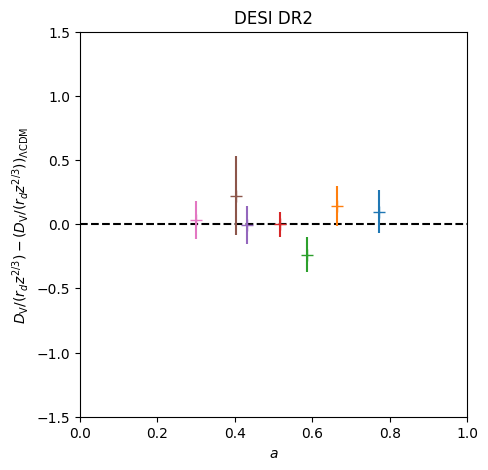

In [859]:
%matplotlib inline 
# ── Plot ──────────────────────────────────────────────────────────────────────

# C0-C6 in standard order: BGS, LRG, LRG, LRG+ELG, ELG, QSO, Ly-α
labels = ["BGS", "LRG", "LRG", "LRG+ELG", "ELG", "QSO", r"Ly-$\alpha$"]
colors = [f"C{i}" for i in range(7)]
a_vals = 1 / (1 + zv_all)

fig, ax = plt.subplots(figsize=(5, 5))
ax.axhline(0, color='k', linestyle='--')

for a, res, err, label, color in zip(a_vals, residuals, ratio_std, labels, colors):
    ax.errorbar(a, res, yerr=err, marker='+', markersize=8, linewidth=1.5,
                color=color, label=label, capsize=0)

ax.set(
    xlabel=r'$a$',
    ylabel=r'$D_\mathrm{V}/(r_d z^{2/3}) - (D_\mathrm{V}/(r_d z^{2/3}))_{\Lambda\mathrm{CDM}}$',
    xlim=(0, 1),
    ylim=(-1.5, 1.5),
    title='DESI DR2',
)

# ── Your theory ───────────────────────────────────────────────────────────────
# Replace my_theory() with your own function returning (z_array, H_array).
h = 0.6766
h*100 = 100*h
OmL = 0.7
stigma = 1.0
mups2 = 4/3
cpr = 0.999
ombh2=0.02242
omch2=0.11933
omega_m = (ombh2+omch2)/h**2

z_arr, H_arr,P_DE, rho_DE, asol = rhopsol(cpr, omega_m, h, OmL, stigma, mups2)
h_interp = interp1d(z_arr, H_arr / H_arr[0], kind='cubic')
pars = camb.CAMBparams()
pars.set_cosmology(h*100=h*100, ombh2=ombh2, omch2=omch2, omk=0)
pars.set_dark_energy_rho_p_a(a_p=asol, a_rho=asol,p=P_DE, rho=rho_DE)
pars.set_for_lmax(2500, lens_potential_accuracy=0)
pars.InitPower.set_params(As=2.1e-9, ns=0.965, r=0)

results = camb.get_background(pars)
rd_theory      = results.get_derived_params()['rdrag']  # Mpc
h*100rd_theory    = h*100 * rd_theory                        
print(h*100rd_theory)

def theory_dv_over_rdz23(z):
    integral, _ = quad(lambda zp: 1/float(h_interp(zp)), 0, z)
    dm = c_kms / h*100rd_theory * integral
    dh = c_kms / h*100rd_theory / float(h_interp(z))
    return (z * dm**2 * dh)**(1/3) / z**(2/3)

a_plot = np.linspace(0.01, 0.99, 2000)
z_plot = 1/a_plot - 1
theory_res = np.array([theory_dv_over_rdz23(z) - lcdm_dv_over_rdz23(z) for z in z_plot])
ax.plot(a_plot, theory_res, color='k', linewidth=1.5, label='My theory')

# ─────────────────────────────────────────────────────────────────────────────


ax.legend(fontsize='small')
fig.tight_layout()


In [78]:
print(f"ΛCDM best fit h*100rd: {h*100rd_bf:.2f}")     
print(f"Theory h*100rd:        {h*100rd_theory:.2f}") 

ΛCDM best fit H0rd: 10157.43
Theory H0rd:        9962.10
